# Learn covariance correction by doing the matrix operations

A covariance describes how measurements fluctuate together. Its inverse,
the **precision**, supplies their weights in a fit. Friedrich and Eifler's
[precision-matrix expansion](https://arxiv.org/abs/1703.07786) starts with a
covariance model and uses simulations to estimate its missing terms.
Only the model covariance needs inversion.

We first calculate with four vectors and a two-by-two matrix. Each code cell
performs the step just explained, and prints its intermediate quantities.
We then check against the shared implementation and study a larger artificial
joint vector. The final sections explain the real-map experiment. This
notebook itself reads **no simulation maps**; the map pilot has its own
explicit driver and saved measurements.

Read the [notes](notes/covariance_from_simulations/covariance_from_simulations.pdf)
for the longer derivation. The main distinction throughout is between an
**observed estimate**, its **average over repeated experiments**, and the
usually unknown **true covariance**. An unbiased estimate can still be poor
in an individual experiment.

## 1. Set up a reproducible, bounded experiment

The wrapper constructs matrices and draws small Gaussian vectors. It imports
no native CosmoLike model and runs no CAMB calculation. The statistical estimators come from the shared
[precision module](../../external_modules/code/cosmolike_core/cosmolike_notebook_utils/covariance/precision.py),
which the forecast driver also uses. Training and validation have separate random-number streams, the
wrapper fixes the analytic model before drawing either stream, and the
experiment never replaces a draw because its estimate is inconvenient. BLAS
uses one worker, including in a reused notebook kernel.

In [1]:
# Setup only: this cell loads the plotting and statistical routines.
# No DES map, cosmological model or covariance calculation is started here.
# Run this notebook from the des_3pcf directory so the paths below refer to
# this checkout rather than another project's compiled interface.
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

# Set workers before importing NumPy. This small example needs one worker;
# BLAS must remain single-threaded in the Cocoa workflow.
for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(PROJECT / "scripts"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
import cosmolike_des_3pcf_precision_wrappers as nw

# A notebook kernel may already have imported a BLAS library. Limit those
# loaded libraries too; environment variables alone would not change them.
blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
# The shared plotting package accepts ordinary arrays and does not run
# this project's native interface. Its name begins with a digit, so importlib
# loads it by its full module name.
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 2. Start with four measured vectors

Each row below represents one independent experiment, with two measurements.
The columns must have the same meaning in every row. First compute the mean
of each column:

$$\bar d_i=\frac{1}{N}\sum_{s=1}^N d_{si}.$$

Subtract this mean from each row to obtain a fluctuation:

$$r_{si}=d_{si}-\bar d_i.$$

A covariance entry measures whether two columns fluctuate together:

$$\widehat C_{ij}=\frac{1}{N-1}\sum_{s=1}^N r_{si}r_{sj}.$$

The denominator is $N-1$ because the same sample estimated its mean. In the
code, `residuals.T @ residuals` performs every pair of column products and
sums over the experiments. `@` means matrix multiplication; `**2` would
square individual entries and would not compute this covariance.

In [3]:
# Four small, deliberately chosen vectors make all the arithmetic visible.
# They teach the covariance calculation; they are not a Gaussian mock suite.
small_vectors = np.array([[1., 1.], [2., 1.], [3., 3.], [4., 3.]])
small_count = small_vectors.shape[0]
small_mean = np.mean(a=small_vectors, axis=0)
small_residuals = small_vectors - small_mean
small_products = small_residuals.T @ small_residuals
small_covariance = small_products / (small_count - 1)
print("Column means:", small_mean)
print("Mean-subtracted rows:\n", small_residuals)
print("Sum of outer products:\n", small_products)
print("Sample covariance:\n", small_covariance)
np.testing.assert_allclose(small_covariance, np.array([[5., 4.], [4., 4.]]) / 3.)

Column means: [2.5 2. ]
Mean-subtracted rows:
 [[-1.5 -1. ]
 [-0.5 -1. ]
 [ 0.5  1. ]
 [ 1.5  1. ]]
Sum of outer products:
 [[5. 4.]
 [4. 4.]]
Sample covariance:
 [[1.66666667 1.33333333]
 [1.33333333 1.33333333]]


## 3. Remove the model's units before comparing covariances

For the next example, imagine that ten independent Gaussian experiments gave
this sample covariance. It is a new example; it is not the four-row sample
above:

$$\widehat C=\begin{pmatrix}4.4&0.4\\0.4&0.9\end{pmatrix}.$$

Our independently specified model predicts

$$M=\begin{pmatrix}4&0\\0&1\end{pmatrix}.$$

Its first measurement has model standard deviation two, and its second has
standard deviation one. The Cholesky factor is the matrix whose product
with its transpose reconstructs the model:

$$M=LL^{\mathsf T}.$$

For this diagonal example, it records the two standard deviations:

$$L=\begin{pmatrix}2&0\\0&1\end{pmatrix}.$$

Dividing each fluctuation by its model scale is called **whitening**. For a
covariance, both the row and the column acquire a scale factor:

$$S=L^{-1}\widehat C L^{-\mathsf T}.$$

For example, its off-diagonal entry becomes

$$S_{12}=\frac{0.4}{2\times1}=0.2.$$

The resulting matrix is dimensionless. General correlated models use the
same operation with a triangular, rather than diagonal, Cholesky factor.

In [4]:
# These are observed example inputs. The true covariance is not specified.
# N counts independent vectors, not pixels, cuts or repeated noise files.
example_count = 10
example_sample = np.array([[4.4, 0.4], [0.4, 0.9]])
example_model = np.diag(v=[4., 1.])
example_identity = np.eye(N=2)
example_factor = np.linalg.cholesky(example_model)
# Solve L times X = I to display L^{-1} for this tiny teaching matrix.
# The shared production routine instead applies triangular solves directly.
example_inverse_factor = np.linalg.solve(example_factor, example_identity)
example_whitened = example_inverse_factor @ example_sample
example_whitened = example_whitened @ example_inverse_factor.T
print("L:\n", example_factor)
print("L inverse:\n", example_inverse_factor)
print("Whitened observed covariance S:\n", example_whitened)

L:
 [[2. 0.]
 [0. 1.]]
L inverse:
 [[0.5 0. ]
 [0.  1. ]]
Whitened observed covariance S:
 [[1.1 0.2]
 [0.2 0.9]]


## 4. Why the square needs its own correction

Call the unknown true covariance in these coordinates $R$:

$$R=L^{-1}CL^{-\mathsf T}.$$

Repeated independent experiments would give different observed matrices
$S$. Their ensemble average is $R$. The precision expansion needs the true
matrix square $R^2$, but simply squaring an observed $S$ also squares its
sampling error. This adds a bias even when $S$ itself is unbiased.

The scalar case makes the effect visible. Take a true dimensionless variance
of 1.1 and five independent Gaussian draws per experiment. After subtracting
the sample mean, the degrees of freedom are

$$\nu=N-1=4.$$

The Gaussian sample-variance identity gives

$$\mathbb E[S^2]=\left(1+\frac{2}{\nu}\right)R^2.$$

Its value is 1.815, although the square we want is only 1.21. Multiply the
observed square by the inverse bias factor:

$$Q=\frac{\nu}{\nu+2}S^2.$$

Now the **expectation** of $Q$ is 1.21. This says nothing about the exact value
of $Q$ in one experiment. We calculate ensemble expectations analytically
below; these printed values are not Monte Carlo estimates.

In [5]:
# The scalar example has its own N=5; it does not replace example_count=10.
scalar_truth = 1.1
scalar_nu = 5 - 1
expected_naive_square = (1. + 2. / scalar_nu) * scalar_truth**2
scalar_multiplier = scalar_nu / (scalar_nu + 2.)
expected_corrected_square = scalar_multiplier * expected_naive_square
print("True variance squared:", scalar_truth**2)
print("Expected observed square:", expected_naive_square)
print("Correction multiplier:", scalar_multiplier)
print("Expected corrected square:", expected_corrected_square)
# One observed S can happen to equal R, but its corrected square still differs.
print("Q for one observed S=1.1:", scalar_multiplier * 1.1**2)
np.testing.assert_allclose(expected_corrected_square, scalar_truth**2)

True variance squared: 1.2100000000000002
Expected observed square: 1.8150000000000004
Correction multiplier: 0.6666666666666666
Expected corrected square: 1.2100000000000002
Q for one observed S=1.1: 0.8066666666666668


## 5. Derive the matrix correction before computing it

Matrices have cross terms that the scalar multiplier cannot remove. For
independent Gaussian vectors, their sample covariance has a Wishart
distribution. Its moment identity for the matrix square is

$$\mathbb E[S^2]=\left(1+\frac{1}{\nu}\right)R^2
 +\frac{R\,\mathrm{tr}(R)}{\nu}.$$

Here the trace is the sum of the diagonal entries. The unwanted second term
contains that trace. A second observable product has exactly the trace
structure needed to cancel it:

$$\mathbb E[S\,\mathrm{tr}(S)]=R\,\mathrm{tr}(R)+\frac{2}{\nu}R^2.$$

Multiply the first identity by $\nu^2$. Multiply the second by $\nu$, then
subtract. The trace terms cancel, leaving

$$\mathbb E[\nu^2S^2-\nu S\,\mathrm{tr}(S)]
 =(\nu^2+\nu-2)R^2.$$

Dividing by the coefficient on the right defines the corrected square:

$$Q=\frac{\nu^2S^2-\nu S\,\mathrm{tr}(S)}{\nu^2+\nu-2}.$$

This requires $N>2$. It corrects an ensemble bias under the Gaussian and
independence assumptions. It neither removes the scatter of $Q$ nor turns
non-Gaussian shear summaries into Gaussian vectors.

### 5.1 Compute the ordinary square and the trace separately

Return to the ten-experiment matrix example. Matrix multiplication gives

$$S^2=\begin{pmatrix}1.25&0.40\\0.40&0.85\end{pmatrix}.$$

For example, the upper-left entry is the row-by-column product

$$(S^2)_{11}=1.1\times1.1+0.2\times0.2=1.25.$$

The trace is a single number:

$$\mathrm{tr}(S)=1.1+0.9=2.$$

Keeping these as separate named arrays makes the difference between matrix
and scalar multiplication visible in the code.

In [6]:
# Matrix multiplication includes off-diagonal products in the diagonal.
example_square = example_whitened @ example_whitened
# The trace is a scalar, so the next cell multiplies every entry by it.
example_trace = np.trace(a=example_whitened)
print("S squared by matrix multiplication:\n", example_square)
print("Trace of S:", example_trace)
print("Entrywise square, which would be WRONG here:\n", example_whitened**2)

S squared by matrix multiplication:
 [[1.25 0.4 ]
 [0.4  0.85]]
Trace of S: 2.0
Entrywise square, which would be WRONG here:
 [[1.21 0.04]
 [0.04 0.81]]


### 5.2 Form the two numerator terms

Ten experiments give nine degrees of freedom. The positive term is

$$\nu^2S^2=\begin{pmatrix}101.25&32.40\\32.40&68.85\end{pmatrix}.$$

The term to subtract is

$$\nu S\,\mathrm{tr}(S)=\begin{pmatrix}19.80&3.60\\3.60&16.20\end{pmatrix}.$$

Subtract corresponding entries, then divide every entry by the same
normalization:

$$\nu^2+\nu-2=9^2+9-2=88.$$

The subtraction removes the ensemble bias of the square. It does not
subtract a physical noise covariance from the measurement.

In [7]:
example_nu = example_count - 1
example_positive_term = example_nu**2 * example_square
example_subtraction = example_nu * example_trace * example_whitened
example_numerator = example_positive_term - example_subtraction
example_denominator = example_nu**2 + example_nu - 2.
example_corrected_square = example_numerator / example_denominator
print("Positive term:\n", example_positive_term)
print("Term subtracted:\n", example_subtraction)
print("Numerator:\n", example_numerator)
print("Denominator:", example_denominator)
print("Corrected square Q:\n", example_corrected_square)
np.testing.assert_allclose(
    example_corrected_square,
    np.array([[81.45, 28.8], [28.8, 52.65]]) / 88.,
)

Positive term:
 [[101.25  32.4 ]
 [ 32.4   68.85]]
Term subtracted:
 [[19.8  3.6]
 [ 3.6 16.2]]
Numerator:
 [[81.45 28.8 ]
 [28.8  52.65]]
Denominator: 88.0
Corrected square Q:
 [[0.92556818 0.32727273]
 [0.32727273 0.59829545]]


## 6. Build the precision and restore the original units

The true residual is the discrepancy from the whitened model:

$$X=R-I.$$

If every eigenvalue of $X$ has magnitude below one, the inverse has a
convergent series. Retaining terms through second order gives

$$(I+X)^{-1}\simeq I-X+X^2.$$

Replacing $X$ by $R-I$ and expanding the brackets gives

$$I-(R-I)+(R-I)^2=3I-3R+R^2.$$

We estimate the linear term with $S$ and the square with $Q$:

$$\widehat P_2=3I-3S+Q.$$

This is a dimensionless precision estimate. A residual in original units
must first be whitened on both sides of its quadratic weight. Therefore
restore the physical precision as

$$\widehat\Psi_2=L^{-\mathsf T}\widehat P_2L^{-1}.$$

The transpose is on the **left** here. Compare with the covariance
transformation earlier; the two orders are different.

In [8]:
# Keep the linear part separate so the reader can see where Q enters.
example_linear_part = 3. * example_identity - 3. * example_whitened
example_polynomial = example_linear_part + example_corrected_square
example_precision = example_inverse_factor.T @ example_polynomial
example_precision = example_precision @ example_inverse_factor
print("3I - 3S:\n", example_linear_part)
print("Dimensionless second-order precision:\n", example_polynomial)
print("Precision in original measurement units:\n", example_precision)
# A valid Gaussian weight must be positive in every direction. Do not clip
# negative eigenvalues to make a failed correction look acceptable.
print("Polynomial eigenvalues:", np.linalg.eigvalsh(example_polynomial))
shared_precision, shared_diagnostics = nw.precision_expansion(
    analytic=example_model,
    sample=example_sample,
    independent_count=example_count,
    order=2,
)
np.testing.assert_allclose(shared_precision, example_precision, rtol=1.e-13)
print("The shared routine agrees with the displayed operations.")

3I - 3S:
 [[-0.3 -0.6]
 [-0.6  0.3]]
Dimensionless second-order precision:
 [[ 0.62556818 -0.27272727]
 [-0.27272727  0.89829545]]
Precision in original measurement units:
 [[ 0.15639205 -0.13636364]
 [-0.13636364  0.89829545]]
Polynomial eigenvalues: [0.45701346 1.06685018]
The shared routine agrees with the displayed operations.


**What this check establishes.** We obtained approximately 0.156392,
and 0.898295 on the diagonal, and −0.136364 off the diagonal. These are
the entries of the restored precision. The check verifies the arithmetic and the call to
the shared routine. We did not specify the true covariance for these ten
experiments, so we cannot infer that this correction improves it.

Three different questions remain: Is the covariance model close enough for
the series to converge? Are the Gaussian sampling identities appropriate?
Are there enough independent simulations to keep the correction's scatter
small? A positive estimate alone does not answer these questions.

## 7. Define what is known and what simulations must estimate

For the larger experiment, the true covariance is

$$C=A+B.$$

Both terms are covariances of random contributions to the same full data
vector. The model retains the known term and approximates the other:

$$M=A+B_m.$$

Here $A$ is known, and $B_m$ imperfectly approximates $B$. The
controlled construction draws independent Gaussian vectors $a$ and $b$ and
forms the measured vector $d=a+b$, so simulating $b$ alone estimates $B$
without the sampling noise of $a$.

This is not a two-point/three-point block split. A matrix containing only a
cross block has zero diagonal variances but nonzero off-diagonal entries; it
is generally indefinite and is not a covariance of random contributions. Nor
does subtracting $A$ from a sample covariance of $d$ make the result a Wishart
sample of $B$. Physical shear summaries are nonlinear functions of signal and
shape noise, so the three-point covariance contains mixed signal/noise powers
as well as noise-only terms, and a diagonal white-noise $A$ does not describe
all noise terms of the Map3 covariance. A survey decomposition of this kind
needs noiseless catalogues, paired realizations or a noise switch that
establish a positive semidefinite $B$ and a known $A$ consistently, including
the two/three-point cross-covariance, the same masks and the same estimator;
the controlled additive-Gaussian construction does not prove one.

The first 12 controlled rows are two-point-like, the last 12
three-point-like, with row scales $10^{-4}$ and $10^{-8}$ chosen to expose
mixed units, not to calibrate a survey. The matrix below keeps the
cross-correlations. The experiment uses $N=18$ training vectors for $p=24$
rows, so the centered full sample cannot have an inverse, and nothing below
attempts one.

Controlled Gaussian joint vectors; not DES simulations.
Training vectors: 18
Rows: 24
Full sample rank: 17
Attempted sample inverse: False
Separate streams: (0,) (1,)


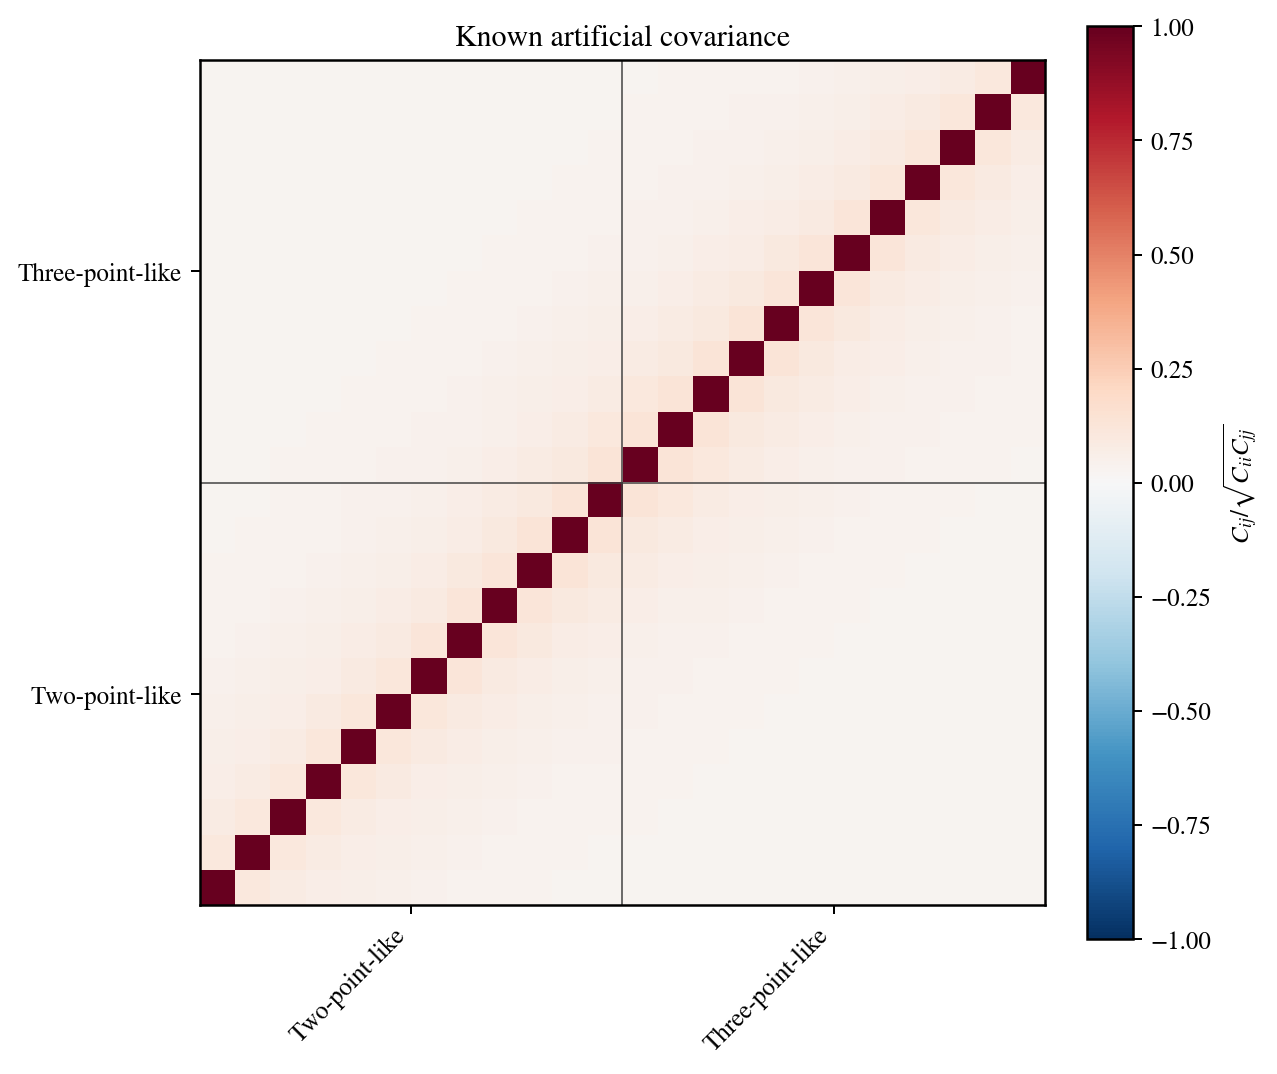

In [9]:
# Use an artificial joint vector whose true covariance is known exactly.
# The first 12 rows mimic two-point measurements and the last 12 mimic
# three-point measurements. Their scales differ, and their cross block is
# nonzero, so the exercise tests the full joint weighting.
# Eighteen training vectors cannot give an invertible 24-row sample
# covariance: after fitting the mean its rank is at most 17.
# PME can still run because it inverts the analytic model, not that sample.
report = nw.controlled_precision_study(
    # Total number of entries in each measured vector.
    ndata=24,
    # Independent draws used to estimate the covariance correction.
    training_count=18,
    # Separate cheap Gaussian draws; these are not additional DES skies.
    validation_count=1200,
    # Fix the teaching experiment so its printed results are reproducible.
    seed=1937,
)
print(report["system"]["scope"])
print("Training vectors:", report["training_count"])
print("Rows:", report["system"]["truth"].shape[0])
print("Full sample rank:", report["sample_rank_in_model_units"])
print("Attempted sample inverse:", report["sample_inverse_attempted"])
print("Separate streams:", report["training_stream"],
      report["validation_stream"])
# Divide covariance entries by their two standard deviations for this plot.
# This displays correlations without hiding the small-unit third-order block.
plots.plot_correlation(
    covariance=report["system"]["truth"],
    labels=["Known artificial covariance", "Reference"],
    block_sizes=[12, 12],
    block_labels=["Two-point-like", "Three-point-like"],
)

### 7.1 Separate truncation error from simulation noise

The small example derived the series in Section 6. Here the controlled
experiment knows the true covariance, so it can evaluate the true residual
matrix and its largest absolute eigenvalue, denoted $\rho$.

When $\rho<1$, the operator-norm remainder after second order is bounded by

$$\frac{\rho^3}{1-\rho}.$$

This is a bound in dimensionless model coordinates. It is not a bound on
every dimensional covariance entry or marginalized parameter error.

The output distinguishes this true truncation error from the error of a
noisy correction. A radius estimated from simulations cannot prove the
unknown true series converges. The exact polynomial is positive for a
symmetric true residual, but its bias-corrected noisy estimate can have
negative eigenvalues. That difference is part of what we test below.

In [10]:
# In this teaching experiment only, we know the true covariance. We can
# therefore distinguish an error in the analytic model from the random
# error caused by estimating that covariance with 18 training vectors.
# The spectral radius is the largest absolute eigenvalue of the whitened
# model error. If the TRUE radius is below one, its inverse series converges.
# The noisy estimated radius is a different quantity; a singular sample
# already has residual eigenvalues of -1 even when the true model is good.
print("True residual spectral radius:",
      report["true_residual_spectral_radius"])
print("Model-unit remainder bound:",
      report["true_second_order_operator_error_bound"])
print("Exact second-order relative precision error:",
      report["diagnostics"]["exact_second_order"]
      ["relative_precision_frobenius_error"])
print("Estimated radii and positivity diagnostics:",
      report["estimator_diagnostics"])

True residual spectral radius: 0.13411494708014332
Model-unit remainder bound: 0.0027859370874408276
Exact second-order relative precision error: 0.0005025586134356025
Estimated radii and positivity diagnostics: {'component': {'estimated_residual_spectral_radius': 0.4024162430184342, 'minimum_polynomial_eigenvalue': 0.653755481036972, 'independent_count': 18, 'order': 2, 'sample_scope': 'separately_simulated_B_covariance'}, 'full': {'estimated_residual_spectral_radius': 2.9396507416907482, 'minimum_polynomial_eigenvalue': -1.9247899444826453, 'independent_count': 18, 'order': 2}}


### 7.2 Correct only a separately simulated component

When simulations genuinely isolate the contribution $B$, whiten its sample:

$$S_B=L^{-1}\widehat B L^{-\mathsf T}.$$

Whiten the independently fixed model for that component too:

$$T=L^{-1}B_mL^{-\mathsf T}.$$

The residual is now the difference between the true whitened component and
$T$. Its squared expansion contains two multiplication orders. Replacing
the unknown component by its sample gives the corrected polynomial

$$\widehat P_{2,B}=I-S_B+T+Q_B-S_BT-TS_B+T^2.$$

Compute $Q_B$ with exactly the operations in Section 5, using $S_B$ in place
of $S$. Keep both cross products; matrices generally do not commute. Restore
units with the same Cholesky factors as in Section 6.

A sample of the **full** vector cannot be used here by subtracting a known
$A$: that difference is not a Wishart sample of $B$. Conversely, adding a
fixed $A$ to a Wishart sample of $B$ does not make a full Wishart covariance.
The controlled experiment below knows which random contribution it drew.
The real shear measurement needs a physically justified decomposition.

**A small check of the two multiplication orders.** Use an identity model
covariance and these two whitened component matrices:

$$S_B=\begin{pmatrix}0.4&0.1\\0.1&0.2\end{pmatrix}.$$

The independently specified component model is

$$T=\begin{pmatrix}0.3&0\\0&0.1\end{pmatrix}.$$

The known covariance contribution is therefore the diagonal matrix with
entries 0.7 and 0.9. In the code, compare the off-diagonal entries of
`S_B @ T` and `T @ S_B`. Each product is asymmetric, but their sum is
symmetric. Dropping one order would change the estimated precision.

In [11]:
# This example supposes ten independent Gaussian B-only vectors.
# It does not obtain B by subtracting a fixed noise term from full vectors.
component_sample = np.array([[0.4, 0.1], [0.1, 0.2]])
component_model = np.diag(v=[0.3, 0.1])
component_nu = 10 - 1
component_square = component_sample @ component_sample
component_trace = np.trace(a=component_sample)
component_q = component_nu**2 * component_square
component_q -= component_nu * component_trace * component_sample
component_q /= component_nu**2 + component_nu - 2.
first_product = component_sample @ component_model
second_product = component_model @ component_sample
component_polynomial = np.eye(N=2) - component_sample + component_model
component_polynomial += component_q
component_polynomial -= first_product
component_polynomial -= second_product
component_polynomial += component_model @ component_model
print("S_B times T:\n", first_product)
print("T times S_B:\n", second_product)
print("Corrected component precision (M is identity):\n", component_polynomial)
component_shared, component_diagnostics = nw.component_precision_expansion(
    analytic=np.eye(N=2),
    component_model=component_model,
    component_sample=component_sample,
    independent_count=10,
    order=2,
)
np.testing.assert_allclose(component_shared, component_polynomial, rtol=1.e-13)

S_B times T:
 [[0.12 0.01]
 [0.03 0.02]]
T times S_B:
 [[0.12 0.03]
 [0.01 0.02]]
Corrected component precision (M is identity):
 [[ 0.88193182 -0.09090909]
 [-0.09090909  0.90375   ]]


### 7.3 A product from independent groups

When Gaussian sampling moments are doubtful, two independent covariance
groups can supply the square instead. Whiten both, obtaining $S_1$ and
$S_2$. Their symmetric cross product is

$$Q_{\rm split}=\frac{S_1S_2+S_2S_1}{2}.$$

Independence makes its expectation equal to the true square. Use their
average in the linear term:

$$\widehat P_{2,\rm split}=3I-3\frac{S_1+S_2}{2}+Q_{\rm split}.$$

This product identity needs independence and unbiased covariances, but not
Gaussian vectors. Splitting a finite budget makes each covariance noisier;
it does not cure truncation error. In the controlled experiment each group
supplies a known $A$ plus an independently estimated $B$. No validation
realization enters either training group.

truth positive_precision relative precision error = 2.7076603902301054e-16
analytic positive_precision relative precision error = 0.03604560126458969
exact_second_order positive_precision relative precision error = 0.0005025586134356025
component_wishart positive_precision relative precision error = 0.19056457595048829
full_wishart refused_nonpositive_precision relative precision error = 1.922485575393032
component_split positive_precision relative precision error = 0.20388279594938835


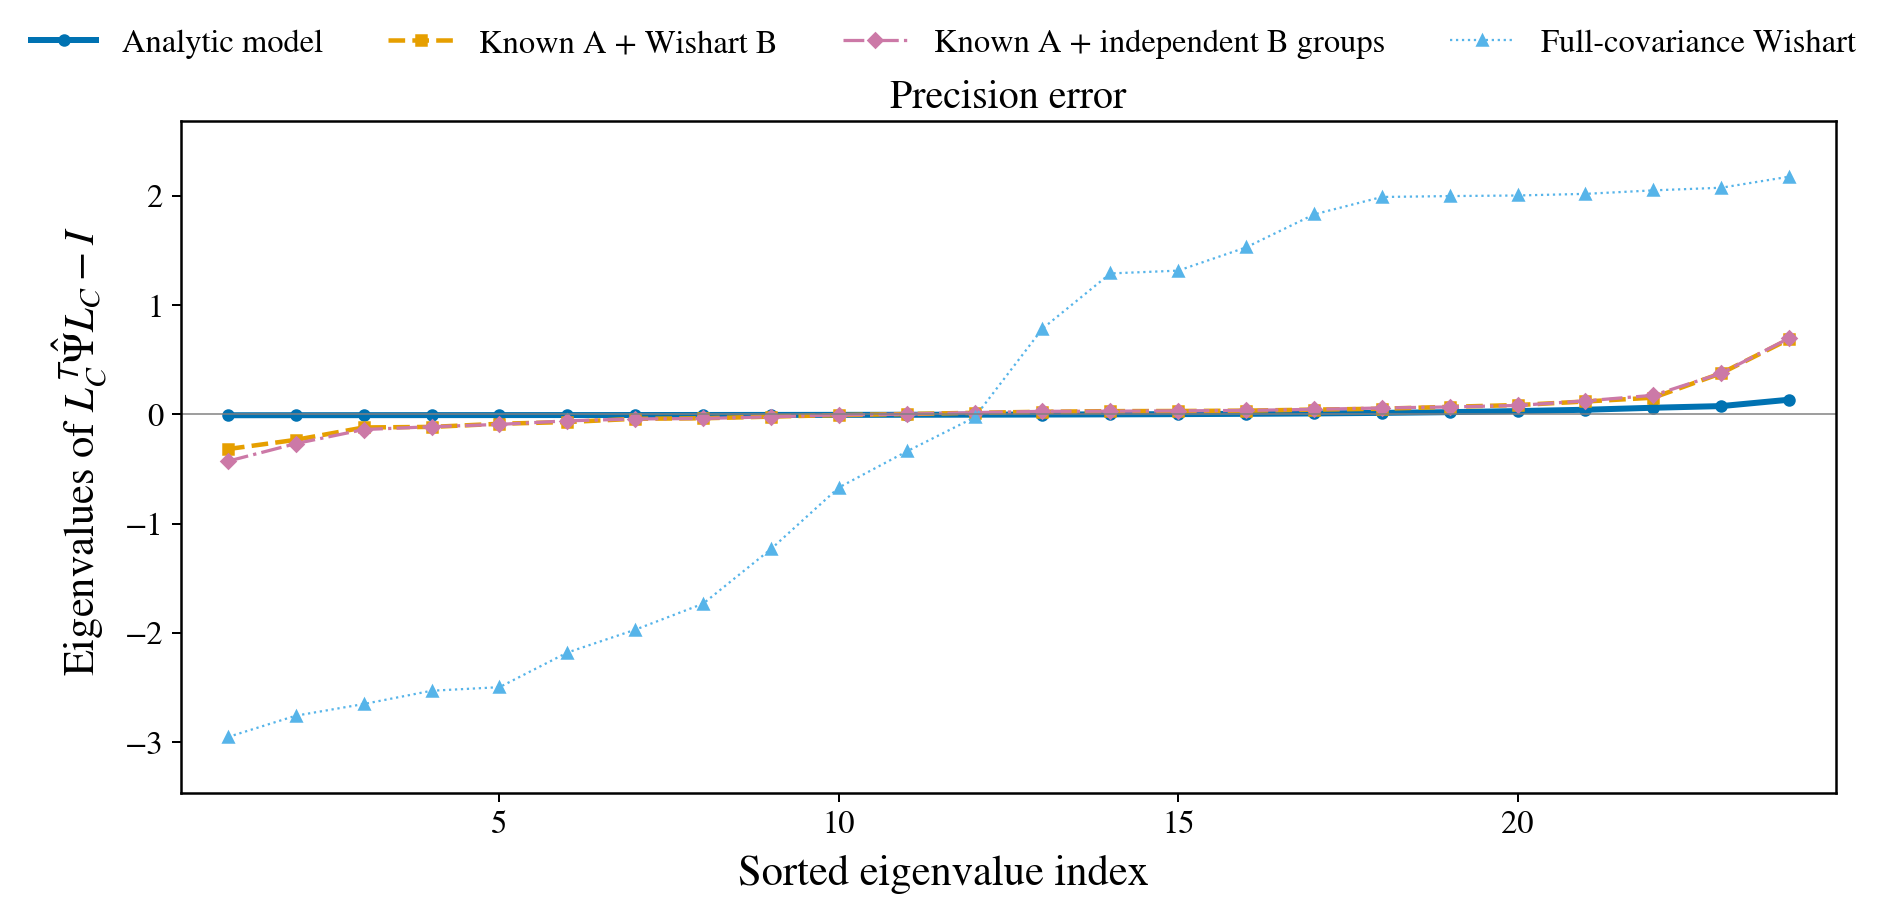

In [12]:
# Compare the analytic model, exact truncated expansion and simulation
# estimates. The exact truncated result isolates the error from omitting
# higher powers; the estimated results also contain finite-sample noise.
# A reported nonpositive precision cannot weight a Gaussian likelihood.
# The plot keeps such failures visible instead of repairing eigenvalues.
for method, diagnostics in report["diagnostics"].items():
    print(method, diagnostics["inference_status"],
          "relative precision error =",
          diagnostics["relative_precision_frobenius_error"])
precision_figure, precision_axes = nw.plot_precision_errors(report=report)
plt.show()

Each line above sorts the eigenvalues of $L_C^{\mathsf T}\widehat\Psi L_C-I$,
where $C=L_CL_C^{\mathsf T}$ factorizes the known true covariance. Zero means
exact precision in that direction, and sorting does not identify a shared
physical eigenvector across methods. An eigenvalue at or below $-1$ marks a
nonpositive precision direction and prohibits using that estimate as a
Gaussian likelihood; the code keeps such a failure in the diagnostic plot,
refuses its parameter errors, and never clips eigenvalues.

One realization need not rank the estimators by their average performance. The
known-component method reduces the source of sampling noise in this
experiment, and its benefit depends on the covariance decomposition and the
quality of the analytic model; the source tests separately compare a small
Gaussian ensemble with the expected truncated series.

In this realization, the analytic model is closer to the true precision than
either noisy correction. Estimating only $B$ reduces the error substantially
relative to estimating the whole covariance, but eighteen training
realizations do not make a correction beneficial relative to this good
analytic starting model; more simulations and independent validation must
decide whether to apply one. The random draw stays as drawn.

## 8. Test the error bars, not only the matrix entries

The controlled model's mean responds linearly to three artificial parameters:

$$\mu=D\boldsymbol p.$$

The columns of $D$ are prescribed responses named amplitude, alignment and
shape. These are teaching labels, not measured DES derivatives. With a
positive precision estimate, the fit's Fisher matrix is

$$F=D^{\mathsf T}\widehat\Psi D.$$

The operation that turns a data vector into a fitted parameter vector is

$$H=F^{-1}D^{\mathsf T}\widehat\Psi.$$

Applying it to one realization gives

$$\widehat{\boldsymbol p}=Hd.$$

The fit quotes parameter covariance $F^{-1}$. Its actual repeated-experiment
covariance instead follows by propagating the true data covariance:

$$C_{p,\rm actual}=HCH^{\mathsf T}.$$

These agree for the true precision, but can differ when an approximate
precision gives the wrong weights. The plots compare quoted errors with the
known truth and with 1,200 independent validation draws. This validates one
estimated precision realization. A coverage study must also repeat the
training experiment.

No parameter contour for Full-covariance Wishart: nonpositive precision.


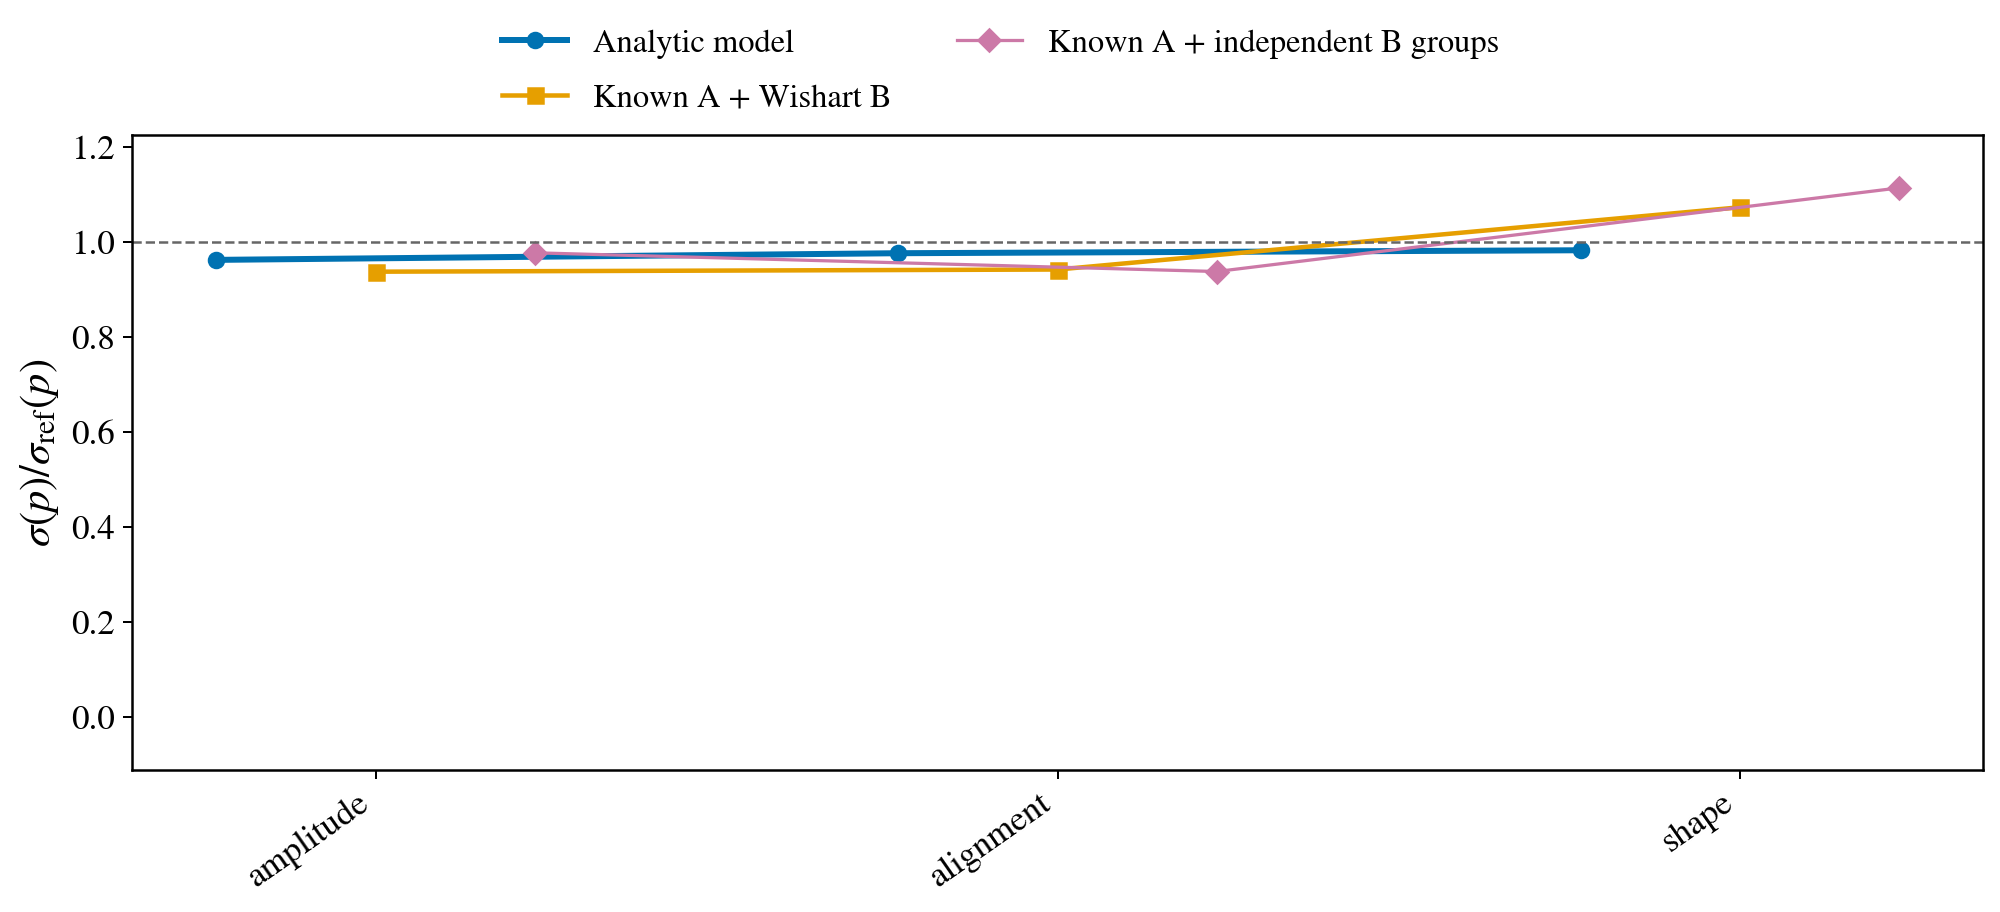

truth
Exact variance / quoted variance: [1. 1. 1.]
Validation variance / quoted variance: [0.9353738  0.9920423  1.01861395]
Validation mean quadratic / row count: 0.9846148847820811
analytic
Exact variance / quoted variance: [1.08189129 1.0510291  1.03793727]
Validation variance / quoted variance: [1.01362679 1.04248163 1.05817678]
Validation mean quadratic / row count: 0.9976727956573369
exact_second_order
Exact variance / quoted variance: [1.00121846 1.00021978 1.00011629]
Validation variance / quoted variance: [0.93652051 0.99225723 1.01873673]
Validation mean quadratic / row count: 0.984744958853503
component_wishart
Exact variance / quoted variance: [1.16523076 1.15038435 0.90063282]
Validation variance / quoted variance: [1.06835777 1.14474793 0.90662449]
Validation mean quadratic / row count: 1.0093599257713866
full_wishart is excluded from parameter inference.
component_split
Exact variance / quoted variance: [1.09929729 1.16097989 0.85663332]
Validation variance / quoted vari

In [13]:
# A good covariance is useful only if it gives reliable parameter errors.
# The teaching model has prescribed derivative columns, so we can compare
# the scatter expected under the known true covariance with the error bars
# that each approximate precision would quote.
# The independent validation vectors provide a second, empirical check.
parameter_figure, parameter_axis = nw.plot_precision_parameter_errors(
    report=report,
)
plt.show()
# A variance ratio of one means the quoted variance matches the scatter.
# Greater than one means the quoted error bar is too small. The validation
# ratio fluctuates because it is estimated from a finite independent sample.
for method, diagnostics in report["diagnostics"].items():
    if diagnostics["positive"]:
        print(method)
        print("Exact variance / quoted variance:",
              diagnostics["exact_variance_over_quoted"])
        print("Validation variance / quoted variance:",
              diagnostics["validation_variance_over_quoted"])
        # This last diagnostic checks the whole data-vector weighting, rather
        # than only the selected parameter directions. The model mean is
        # known here; fitting a mean would change the reference expectation.
        print("Validation mean quadratic / row count:",
              diagnostics["validation_mean_quadratic_per_row"])
    else:
        print(method, "is excluded from parameter inference.")

## 9. Replace the controlled vectors with real joint realizations

A real archive must contain `vectors[N,p]`, ordered `row_labels[p]`,
`row_kind[p]`, `parent_ids[N]`, and the scalar string `estimator`. The loader
checks the row labels, row kinds and the estimator string, and it never
reorders columns. Those checks are necessary, not sufficient: the name
`finite_sas`, the finite side-angle-side estimator, does not encode triangle
cuts, bin averages, weights, masks or source calibration. The analyst must
compare a recorded estimator and input manifest for the simulations and the
analytic calculation, including the joint cross-covariance and the source
ordering. `excluded_parent_ids` records skies that tuned the analytic model or
validated the result; the loader refuses overlap with training.

The public Y3 construction's 796 patches come from 199 parent skies, so they
are not 796 independent realizations merely because they occupy separate rows
in a file. The loader refuses repeated parent IDs, and it does not average
patches, because averaging would change the estimator and the covariance. The
analyst must construct a defensible independent realization set or derive a
correlated-realization correction; a file count alone justifies no Wishart
degree-of-freedom choice.

For a full joint simulation archive, the intended calls are:

```python
simulation = nw.load_joint_simulations(
    path=PROJECT / "chains" / "independent_joint_vectors.npz",
    expected_labels=analytic_row_labels,
    expected_kind=analytic_row_kind,
    expected_estimator="finite_sas",
    excluded_parent_ids=validation_and_tuning_parents,
)
sample = nw.covariance_of_vectors(vectors=simulation["vectors"])
precision, diagnostics = nw.precision_expansion(
    analytic=analytic_covariance,
    sample=sample,
    independent_count=simulation["independent_count"],
    order=2,
)
```

These lines are a file contract, not a claim that such independent DES
realizations exist. The component version also needs simulations whose
covariance really is $B$ and a validated independent $A$; the demonstrated PME
is also not a Hartlap rescaling, a multivariate-t likelihood, or a correction
for errors in the mean model.

The compiled covariance covers the full-filter gravitational model and its
chosen terms; it is not a converged, estimator-matched finite-SAS TATT
covariance for this DES example. This notebook teaches the correction method
and leaves that physical covariance and the missing independent survey
realizations as separate work.

## 10. What Rafael's downloaded maps contain

**Rafael confirmed:** these are CosmoGrid shear maps at NSIDE 512. Only
pixels with nonzero DES footprint are stored; `indices_512.npy` identifies them.
The [folder guide](maps_cov_512_v2/README.md) and
[viewing notebook](maps_cov_512_v2/EXAMPLE_VIEW_MAPS.ipynb) explain how to
recover and display the footprint. The index file has 369,190 unique integer entries matching the map axis.
The viewing notebook compares both orderings: RING recovers the DES footprint;
NESTED does not. This is geometric evidence, not producer confirmation of
the shear-component signs or basis.

Only `run_0000_ncut0_nreal0` and `run_0000_ncut0_nreal1` were inspected.
Both arrays have shape `(4, 2, 369190)` and dtype `float64`. A bounded sample
of their first 4,096 pixels in each slot was finite. Four source bins and
two components are consistent with the shape, but their ordering and signs
must be confirmed. Do not reshape the last axis into an image: position
`j` refers to sky pixel `indices[j]`.

There are three different objects here:

| Object | What one row or entry means | Used for |
|---|---|---|
| Shear map | A component at one retained sky pixel | Measuring correlations |
| Joint vector | One xi or aperture statistic in a specified bin | Estimating a covariance |
| Parent simulation | One independently generated density realization | Counting cosmic-variance information |

The file labels suggest `run` is the parent, `ncut` a footprint and `nreal`
a noise realization. This interpretation is **not confirmed** by the pixel
message. Keep provisional groups intact until the producer specifies their
meaning. A new file does not by itself increase the independent sky count.
The directory is ignored by Git except for its guide and viewing notebook.

## 11. Restore the noise of one survey after averaging repeated draws

Suppose different `nreal` labels mean conditionally independent noise draws
of one parent sky and one fixed footprint. Define $B$ as the covariance
across skies of their conditional mean measurement. Define $A$ as the
within-sky noise covariance, averaged over skies. One observed survey has

$$C=B+A.$$

Averaging $K$ measured vectors of one parent reduces its noise by $K$.
Therefore the covariance of those parent means has expectation

$$\mathbb E[\widehat C_{\bar d}]=B+\frac{A}{K}.$$

The average within-parent sample covariance, $\widehat A$, estimates $A$.
Subtract its contribution to the parent means to estimate $B$:

$$\widehat B=\widehat C_{\bar d}-\frac{\widehat A}{K}.$$

To recover the covariance of **one** noisy survey, add back one full copy of
the noise term:

$$\widehat C=\widehat B+\widehat A.$$

Inserting the previous expression gives the computable form

$$\widehat C=\widehat C_{\bar d}+\left(1-\frac1K\right)\widehat A.$$

The following scalar calculation mirrors the notes. It uses exact expected
values, so it isolates the missing-noise effect from finite-sample scatter.

In [14]:
# Sky-to-sky variance is 4; the noise of one survey contributes another 9.
# Twenty redraws reduce the noise of a parent mean to 9/20, not to zero.
noise_draws = 20
sky_variance = 4.
noise_variance = 9.
parent_mean_variance = sky_variance + noise_variance / noise_draws
estimated_sky_variance = parent_mean_variance - noise_variance / noise_draws
restored_survey_variance = estimated_sky_variance + noise_variance
print("Variance of parent means:", parent_mean_variance)
print("After subtracting their residual noise:", estimated_sky_variance)
print("After restoring one survey's noise:", restored_survey_variance)
np.testing.assert_allclose(restored_survey_variance, 13.)

Variance of parent means: 4.45
After subtracting their residual noise: 4.0
After restoring one survey's noise: 13.0


This calculation requires equal $K$, the same measurement and footprint,
independent parents, and independent noise draws conditional on each parent.
Different cuts of one sky remain grouped with that sky. Averaging maps before
measuring a nonlinear statistic does not perform this calculation: average
the **measured vectors** instead.

The difference defining $\widehat B$ is not a Wishart sample covariance.
Do not pass it to the component correction with the number of files as its
degrees of freedom. The repeated-draw identity can improve covariance
estimation while still needing a separate treatment of noisy matrix products.

## 12. A small first experiment, followed by a real validation

First confirm the parent/noise labels, coordinates, ordering, shear basis,
source distributions and weights. Select a small, explicit set of complete
files. Measure both xi and Map3 on each of the **same** selected maps;
concatenate their rows before forming the sample covariance. Estimating
the two diagonal blocks separately would discard the cross-covariance we
need to assess the benefit of combining them.

As an initial independent-sky construction, use one preselected cut and one
preselected noise realization per independent parent. This discards some
repeats but makes the sample definition testable. Split at the parent level
into training and validation; reserve separate parents if tuning the
analytic model. More cuts per sky require a study of their correlations,
not a larger integer passed to PME.

[Rafael's methods paper](https://arxiv.org/html/2503.03964v2#S3) describes
NSIDE 1024 maps. The supplied maps have NSIDE 512, with a pixel scale about
6.87 arcminutes rather than 3.44. The paper's small-triangle cuts and pixel
treatment cannot simply be reused. Test resolution, angular cuts and bin
weights with matched analytic predictions before making a DES claim. Where
higher-resolution counterparts are unavailable, retain this as an unresolved
systematic rather than calling the coarse-map result converged.

For measured vectors in `chains/`, the full-covariance call in Section 6 is
the first available route. First order avoids estimating a squared sample
covariance; second order uses a Gaussian/Wishart assumption. Joint aperture
vectors need not be Gaussian. As a further diagnostic, two disjoint parent
groups can supply `split_precision_expansion`: independence makes their
cross-product unbiased for the covariance square without Gaussianity.
It still has sampling variance and truncation error; hold out a third group
for validation. These are future measured-vector calculations, not jobs
started by opening this notebook.

Compare the analytic precision and the corrected precision with identical
mean models, derivatives, priors and data rows. Check positive definiteness,
parameter-error changes, and recovery on held-out mocks. A smaller ellipse
alone is not success: its claimed coverage must agree with the scatter of
recovered parameters. No eigenvalue clipping or Hartlap factor should be
added to hide a failed PME estimate. The notes explain the distinction
between a noisy residual diagnostic and the true convergence condition.

The executed [map experiment](EXAMPLE_COVARIANCE_MAPS.ipynb) now applies
this workflow to coarse aperture moments from Rafael's files. Its Gaussian
reference is calibrated on separate maps, and its first small correction
fails the positivity check. Read its measurement definition and assumptions
before interpreting those results as evidence about the DES likelihood.